<a href="https://colab.research.google.com/github/malak-dotcom/life-expectancy-data-processing/blob/main/adult_processing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import RobustScaler

In [ ]:
df=pd.read_csv('adult.csv')
print(df)
print('\ndf columns=',df.columns)
print('\n df frist 5 samples=',df.head())
print('\n df last 5 samples=',df.tail())
print('\n No.of(r,c)=',df.shape)
print('\n info=',df.info())
print('\n describe num',df.describe())
print('\n describe nonnum',df.describe(include='object'))
print('\n data type=',df.dtypes)


       age     workclass  fnlwgt     education  educational-num  \
0       25       Private  226802          11th                7   
1       38       Private   89814       HS-grad                9   
2       28     Local-gov  336951    Assoc-acdm               12   
3       44       Private  160323  Some-college               10   
4       18             ?  103497  Some-college               10   
...    ...           ...     ...           ...              ...   
48837   27       Private  257302    Assoc-acdm               12   
48838   40       Private  154374       HS-grad                9   
48839   58       Private  151910       HS-grad                9   
48840   22       Private  201490       HS-grad                9   
48841   52  Self-emp-inc  287927       HS-grad                9   

           marital-status         occupation relationship   race  gender  \
0           Never-married  Machine-op-inspct    Own-child  Black    Male   
1      Married-civ-spouse    Farming-fishin

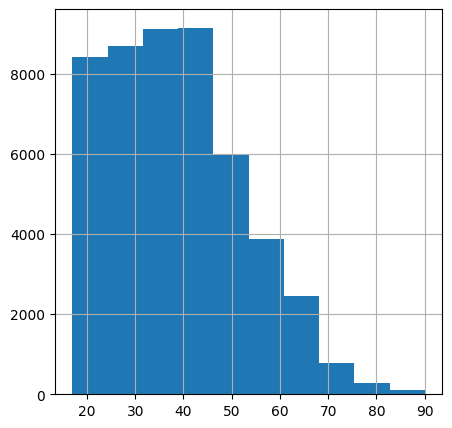

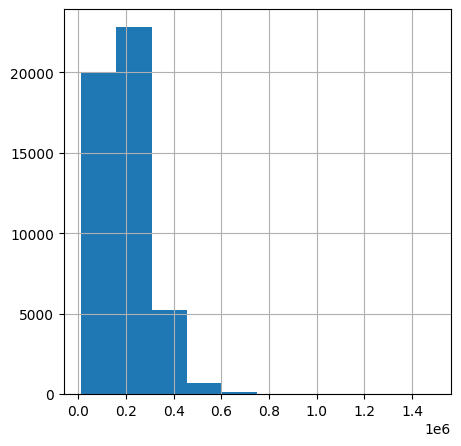

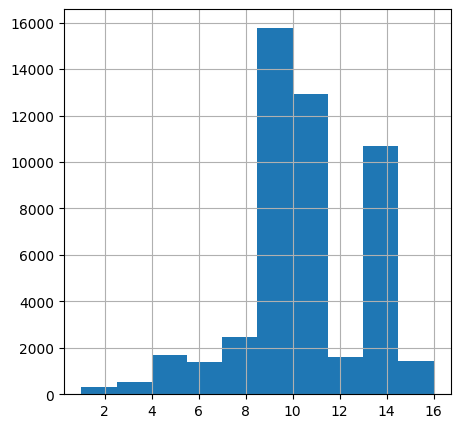

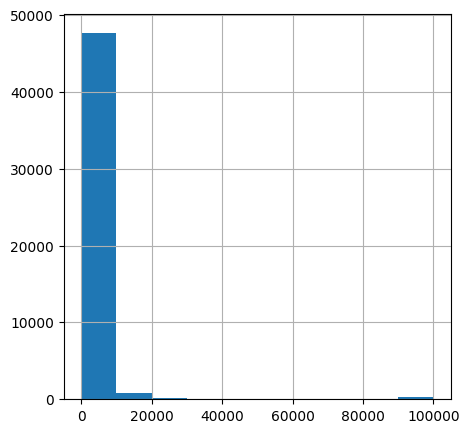

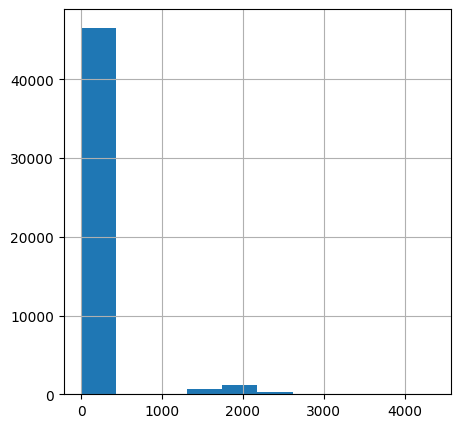

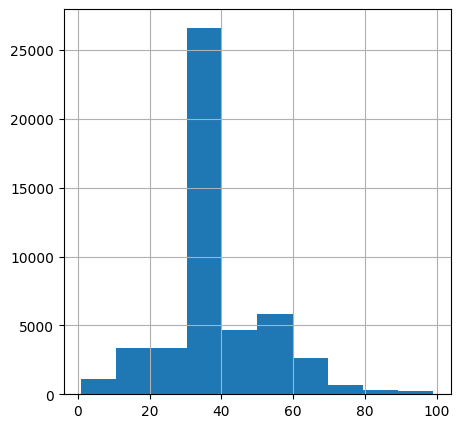

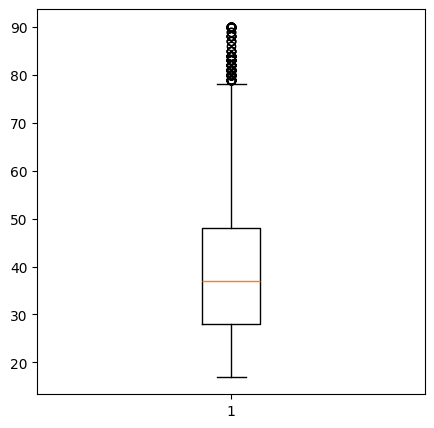

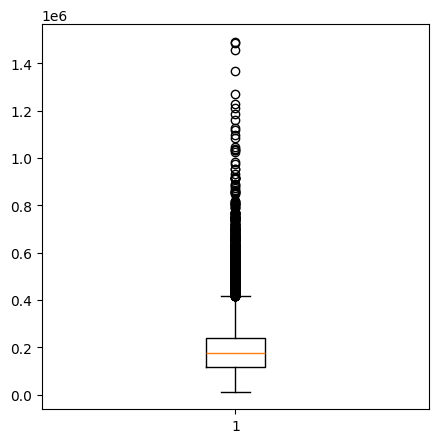

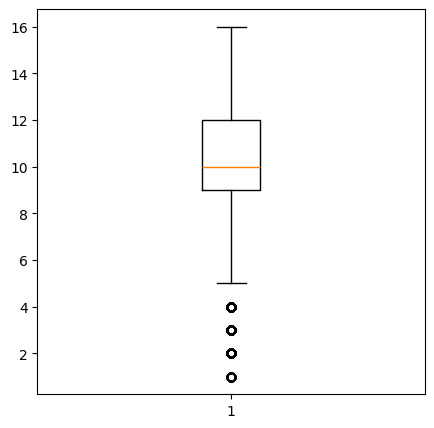

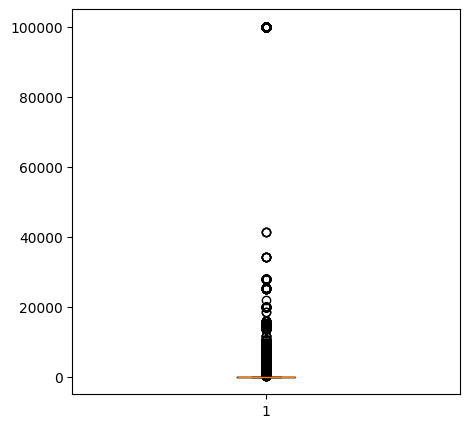

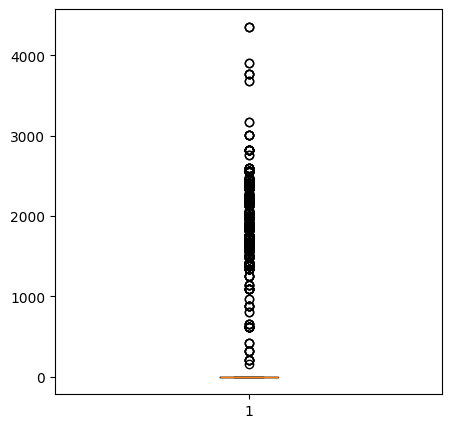

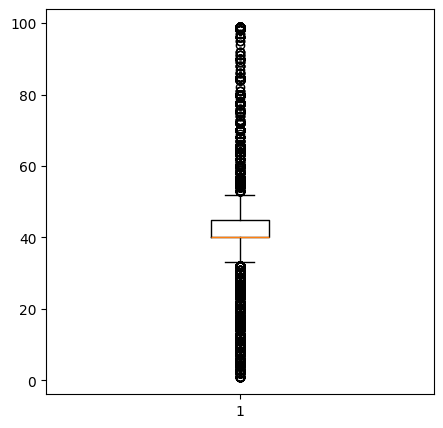

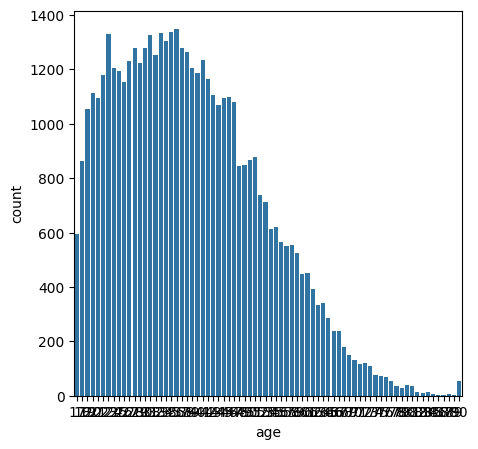

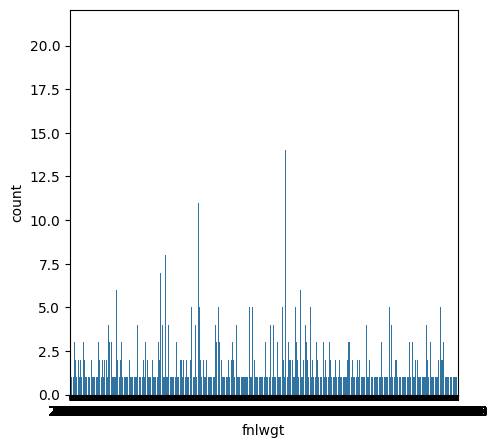

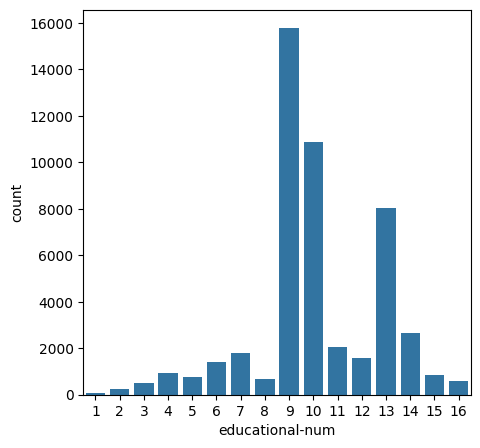

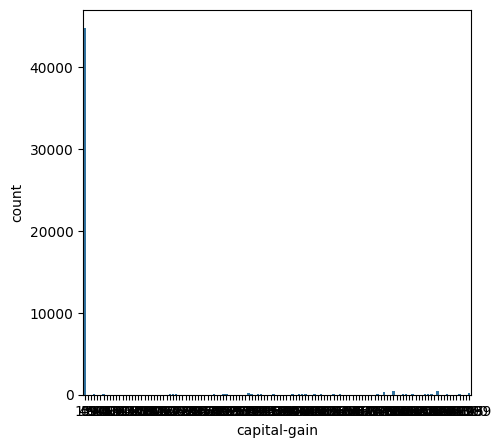

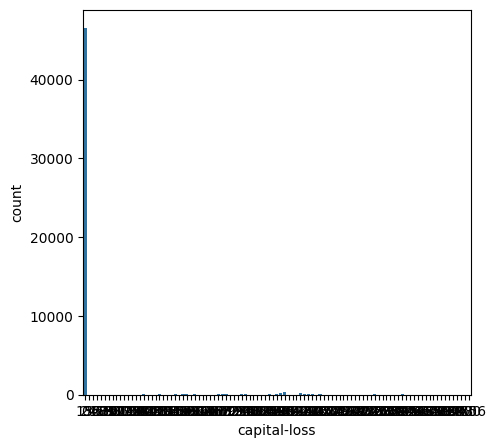

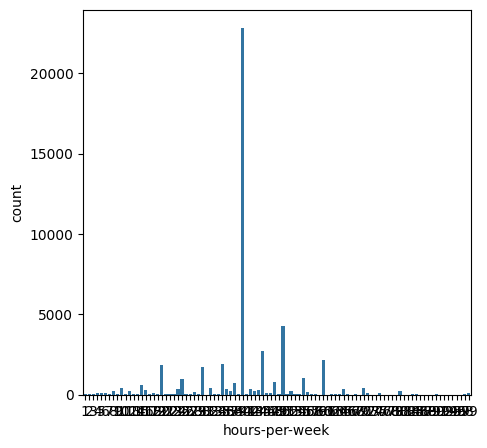

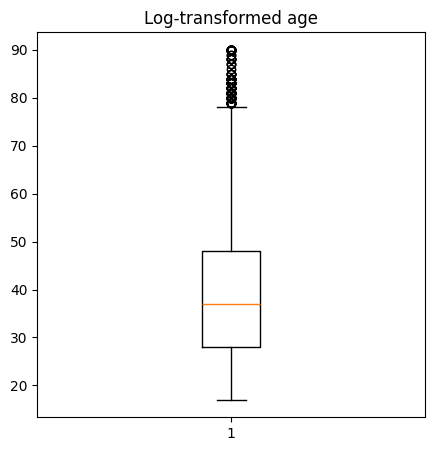

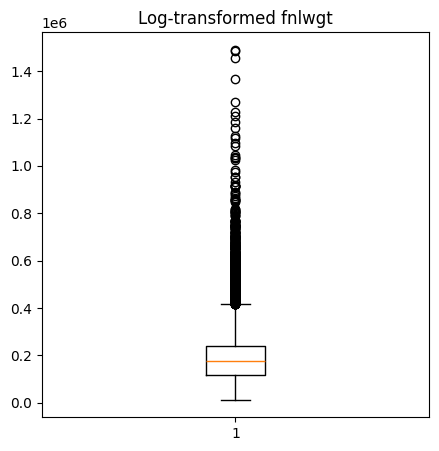

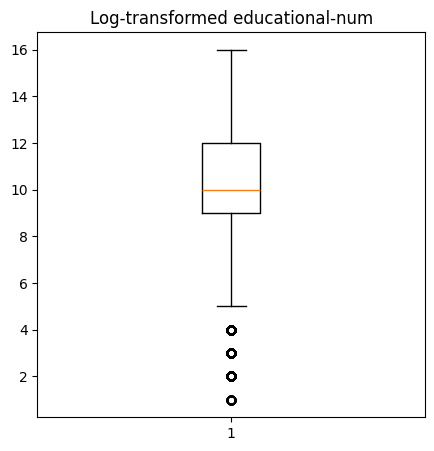

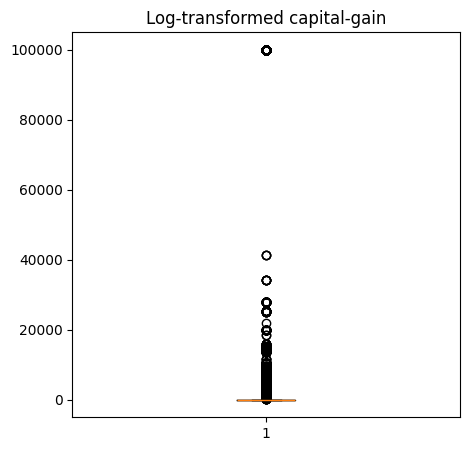

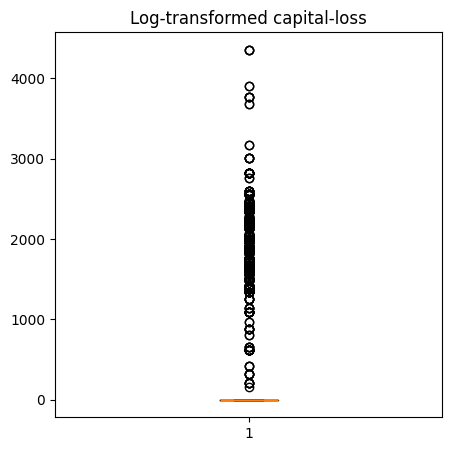

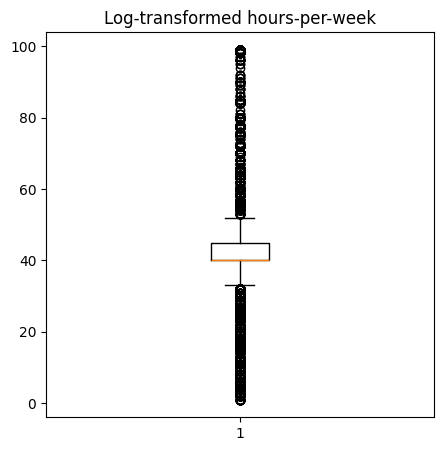

In [ ]:
#1 histograme
num_columns=df.select_dtypes(include=np.number).columns
for col in num_columns:
  plt.figure(figsize=(5,5))
  df[col].hist()
  plt.show()

#2 boxplot
num_columns=df.select_dtypes(include=np.number).columns
for col in num_columns:
  plt.figure(figsize=(5,5))
  plt.boxplot(x=df[col])
  plt.show()

 # 4countplot
num_columns=df.select_dtypes(include=np.number).columns
for col in num_columns:
  plt.figure(figsize=(5,5))
  sns.countplot(x=df[col])
  plt.show()

#transformation
for col in num_columns:

  df[f'{col}_log'] = np.log(df[col].replace(0, np.nan).fillna(1))
  plt.figure(figsize=(5,5))
  plt.boxplot(x=df[col])
  plt.title(f'Log-transformed {col}')
  plt.show()

In [ ]:
#duplicates
df.drop_duplicates(inplace=True)
print(df.shape)
#normalization
from sklearn.preprocessing import StandardScaler
for col in num_columns:
  df[f'{col}_norm'] = (df[col] - df[col].min()) / (df[col].max() - df[col].min())
#encoding
df = pd.get_dummies(df, drop_first=True)


SyntaxError: incomplete input (330522206.py, line 10)

       age     workclass  fnlwgt     education  educational-num  \
0       25       Private  226802          11th                7   
1       38       Private   89814       HS-grad                9   
2       28     Local-gov  336951    Assoc-acdm               12   
3       44       Private  160323  Some-college               10   
4       18             ?  103497  Some-college               10   
...    ...           ...     ...           ...              ...   
48837   27       Private  257302    Assoc-acdm               12   
48838   40       Private  154374       HS-grad                9   
48839   58       Private  151910       HS-grad                9   
48840   22       Private  201490       HS-grad                9   
48841   52  Self-emp-inc  287927       HS-grad                9   

           marital-status         occupation relationship   race  gender  \
0           Never-married  Machine-op-inspct    Own-child  Black    Male   
1      Married-civ-spouse    Farming-fishin

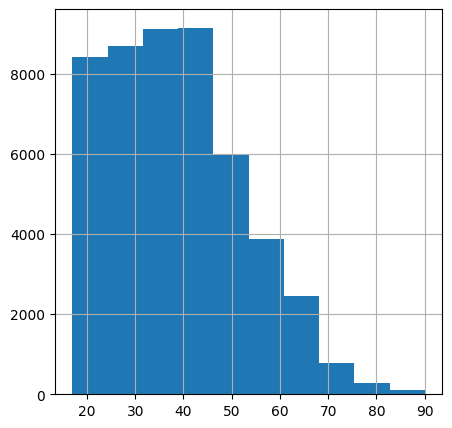

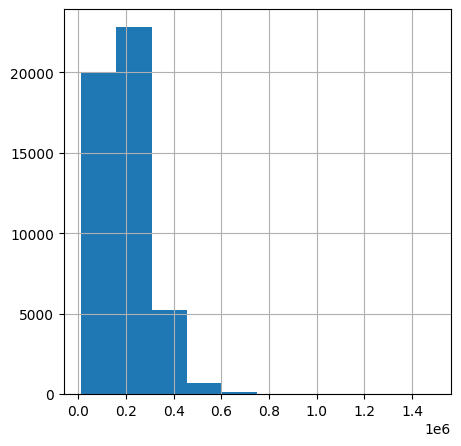

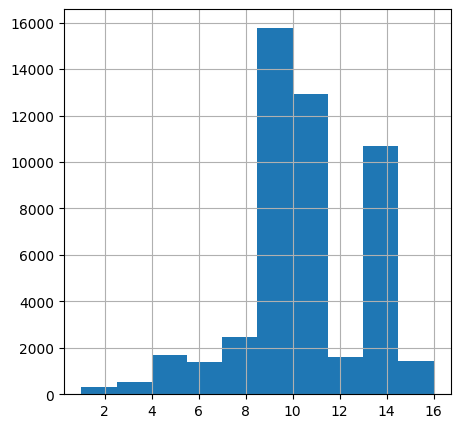

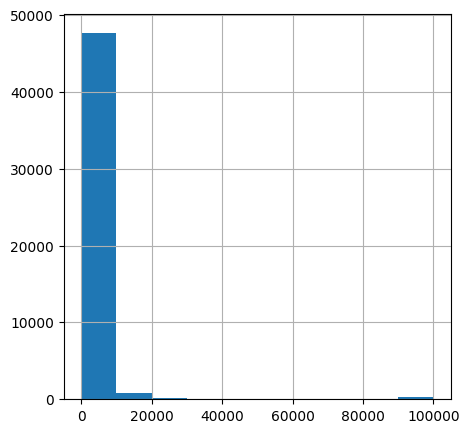

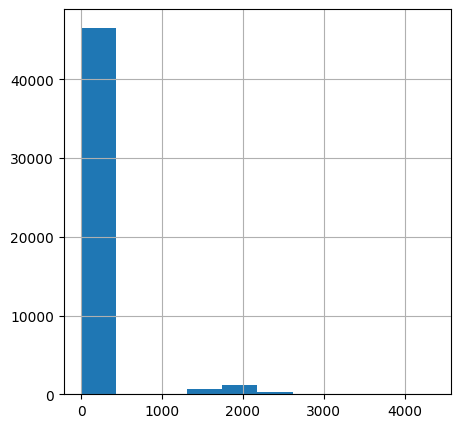

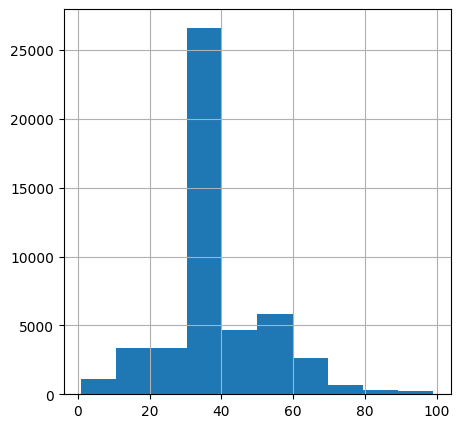

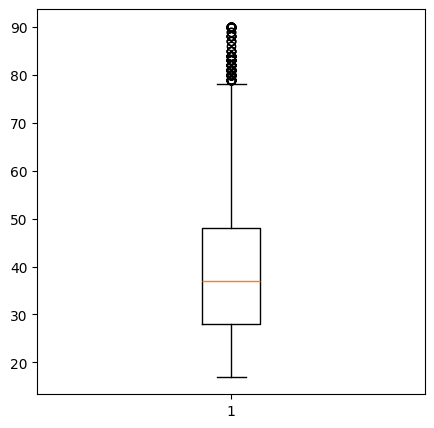

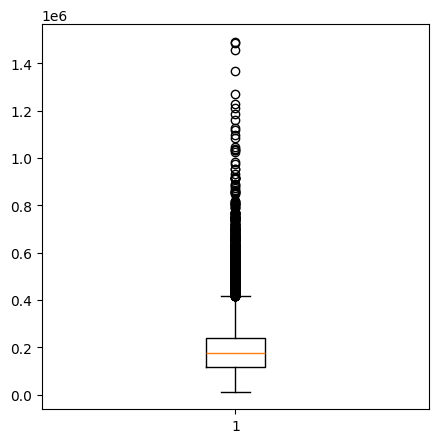

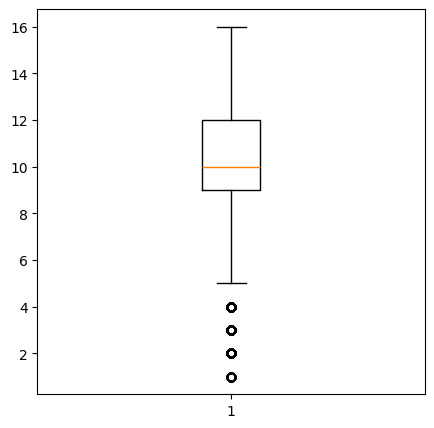

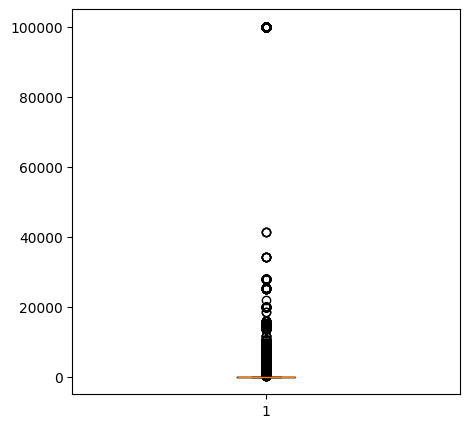

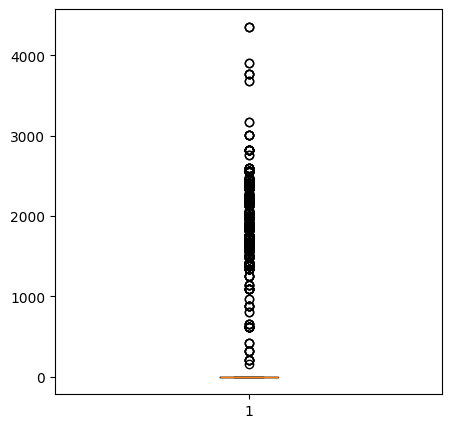

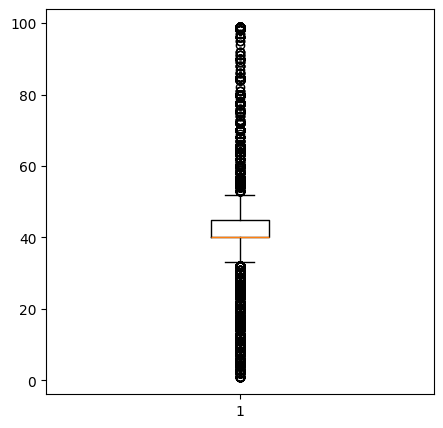

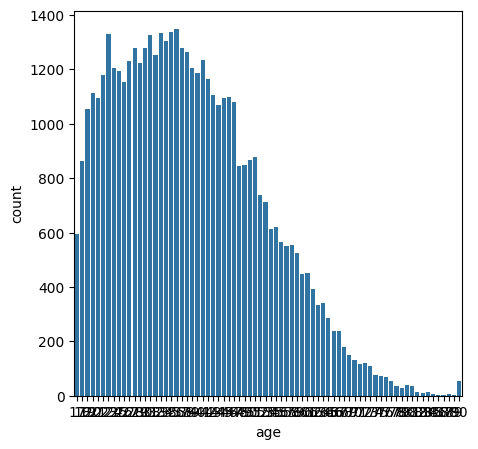

KeyboardInterrupt: 

Error in callback <function _draw_all_if_interactive at 0x7d76e1162840> (for post_execute):


KeyboardInterrupt: 

Error in callback <function flush_figures at 0x7d76e114fd80> (for post_execute):


KeyboardInterrupt: 

In [ ]:

scaler = RobustScaler()
df['fnlwgt'] = scaler.fit_transform(df['fnlwgt'])
#sampling
print('income1',df["income_>50K"].value_counts())

from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
X = df.drop('income_>50K', axis=1)
y = df['income_>50K']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
smote = SMOTE(random_state=42)
X_train, y_train = smote.fit_resample(X_train, y_train)
print('income2',df["income_>50K"].value_counts())
